Воронов, ИУ9-72Б, 6 вариант

пункт 1.

В качестве набора возьмем предлагаемую подвыборку MNIST. Там решается задача классификации, так что сразу оговоримся, что будем всюду далее считать функцией потерь кросс-энтропию.

Теперь касательно модели. В ней 1 скрытый слой и 1 выходной, то есть 2 слоя. В скрытом было принято решение 64 нейрона иметь. В качестве активации на скрытом стоит выбрать тангенциальную, так как в пункте 4 требуется исследовать на то, что потери будут к бесконечности стремится, можно было бы и сигмоидную, но там производная ограниченна еще сильнее и обучение просто дольше будет идти. В реализации конкретно не будем использовать активацию на выходном слое, так как будем использовать CrossEntropyLoss из торча, которая под капотом сама делает софтмакс. И в целом все обучение будем через торч делать, кроме коррекции весов, то есть градиент получим через торч, а затем его и будем использовать для корректировки.

Анализировать в этой части, как влияет скорость обучения не будем, так как это надо сделать в следующем пункте-там же и анализы будут. В этом пункте чисто обучить надо.

In [ ]:
import math
import os
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.metrics import precision_recall_fscore_support

if os.path.exists('mnist_784.npz'):
    d = np.load('mnist_784.npz')
    X_all, y_all = d['X'], d['y']
else:
    mnist = fetch_openml('mnist_784', version = 1, as_frame = False)
    X_all = mnist.data.astype(np.float32) / 255.0
    y_all = mnist.target.astype(np.int64)
    np.savez_compressed('mnist_784.npz', X = X_all, y = y_all)

N_TRAIN = 2000
N_TEST = 500
X_train_np = X_all[:N_TRAIN]
y_train_np = y_all[:N_TRAIN]
X_test_np = X_all[60000:60000 + N_TEST]
y_test_np = y_all[60000:60000 + N_TEST]

mu  = X_train_np.mean()
std = X_train_np.std()
X_train_np = (X_train_np - mu) / std
X_test_np = (X_test_np  - mu) / std
X_train = torch.tensor(X_train_np, dtype=torch.float32)
y_train = torch.tensor(y_train_np, dtype=torch.long)
X_test = torch.tensor(X_test_np,  dtype=torch.float32)
y_test = torch.tensor(y_test_np,  dtype=torch.long)

In [ ]:
loss_fn = torch.nn.CrossEntropyLoss()
def classification_metrics(y_true, logits):
    y_pred = logits.detach().cpu().numpy().argmax(axis=1)
    y_true_np = y_true.cpu().numpy()
    acc = (y_pred == y_true_np).mean().item()
    prec, rec, f1, _ = precision_recall_fscore_support(y_true_np, y_pred, average='weighted', zero_division=0)
    ce = loss_fn(logits, y_true).item()
    return {
        'acc': acc,
        'prec': float(prec),
        'rec': float(rec),
        'f1': float(f1),
        'ce': ce,
    }
def forward(X, W1, b1, W2, b2):
    z1 = X @ W1 + b1
    a1 = torch.tanh(z1)
    return a1 @ W2 + b2
def train_gd(X_tr, y_tr, X_te, y_te, seed, lr=1e-2, n_epochs=500, sigma=0.02):
    g = torch.Generator().manual_seed(seed)
    W1 = (torch.randn(784, 64, generator=g) * sigma).requires_grad_(True)
    b1 = torch.zeros(64, requires_grad=True)
    W2 = (torch.randn(64,  10, generator=g) * sigma).requires_grad_(True)
    b2 = torch.zeros(10, requires_grad=True)
    train_losses = []
    for epoch in range(n_epochs):
        logits = forward(X_tr, W1, b1, W2, b2)
        loss   = loss_fn(logits, y_tr)
        W1.grad = None
        b1.grad = None
        W2.grad = None
        b2.grad = None
        loss.backward()
        W1.data = W1.data - lr * W1.grad
        b1.data = b1.data - lr * b1.grad
        W2.data = W2.data - lr * W2.grad
        b2.data = b2.data - lr * b2.grad
        train_losses.append(loss.item())
    with torch.no_grad():
        logits_te = forward(X_te, W1, b1, W2, b2)
    final = classification_metrics(y_te, logits_te)
    return train_losses, final

In [ ]:
seeds = [42, 0, 1, 2, 3]
lrs = (10 ** torch.linspace(-5, 0, 15)).tolist()
rows, histories = [], {}
for lr in lrs:
    for s in seeds:
        tr_loss, final = train_gd(X_train, y_train, X_test, y_test, seed=s, lr=lr)
        rows.append({
            'lr': lr,
            'seed': s,
            'acc': final['acc'],
            'prec': final['prec'],
            'rec': final['rec'],
            'f1': final['f1'],
            'ce': final['ce'],
        })
        histories[(lr, s)] = tr_loss

Вывод по пункту 1.

Обучили модель с 2 слоями. Обучение прошло в целом успешно, то есть хотя бы нигде не разошлись потери, на маленьких скоростях только наблюдается недообучение. Основной анализ будет приведен в пункте 2, так как он предусматривает это.

Пункт 2.

Тут уже проанализируем результаты обучения в зависимтости от скорости. Кривые потерь на малых шагах будут выглядеть как прямая (то есть мы плавно и неспеша катимся вниз по графику потерь), на больших следует ожидать резкого падения в начале (так как быстрая скорость падения), но затем уже далее график не будет скорее идти вниз (так как шаги будут довольно большими и не выйдет минимума уже достигнуть скорее), то есть график что-то вроде ветви гиперболы.

Исходя из вышенаписанного можно сделать вывод, что окно оптимального шага будет не по краям сетки, а где-то внутри (то есть шаг не слишком большой и не слишком маленький).

In [ ]:
summary = []
for lr in lrs:
    n = s_acc = sq_acc = s_prec = s_rec = s_f1 = s_ce = sq_ce = 0.0
    acc_min = float('inf')
    acc_max = float('-inf')
    for r in rows:
        if r['lr'] == lr:
            s_acc += r['acc']
            sq_acc += r['acc'] ** 2
            s_prec += r['prec']
            s_rec += r['rec']
            s_f1 += r['f1']
            s_ce += r['ce']
            sq_ce += r['ce'] ** 2
            n += 1
            if r['acc'] < acc_min:
                acc_min = r['acc']
            if r['acc'] > acc_max:
                acc_max = r['acc']
    mean_acc = s_acc / n
    std_acc = ((sq_acc - n * mean_acc ** 2) / (n - 1)) ** 0.5
    mean_ce = s_ce / n
    std_ce  = ((sq_ce - n * mean_ce ** 2) / (n - 1)) ** 0.5
    summary.append({
        'lr': lr,
        'acc': mean_acc,
        'acc_std': std_acc,
        'acc_min': acc_min,
        'acc_max': acc_max,
        'prec': s_prec / n,
        'rec': s_rec  / n,
        'f1': s_f1   / n,
        'ce': mean_ce,
        'ce_std': std_ce,
    })
for r in summary:
    print(f"lr {r['lr']} acc {r['acc']} acc_std {r['acc_std']} prec {r['prec']} rec {r['rec']} f1 {r['f1']} ce {r['ce']}")

lr 9.999999747378752e-06 acc 0.0824 acc_std 0.030013330371686516 prec 0.12701548414094813 rec 0.0824 f1 0.0721662315251366 ce 2.307086133956909
lr 2.2758462364436127e-05 acc 0.0892 acc_std 0.03375203697556638 prec 0.13275254437246248 rec 0.0892 f1 0.07827112443521642 ce 2.304878807067871
lr 5.179476283956319e-05 acc 0.10400000000000001 acc_std 0.04166533331199927 prec 0.14227631205008712 rec 0.10400000000000001 f1 0.09126811565648142 ce 2.2998713493347167
lr 0.00011787685070885345 acc 0.142 acc_std 0.04967896939349693 prec 0.18362542273055943 rec 0.142 f1 0.12626119810915698 ce 2.288531494140625
lr 0.00026826959219761193 acc 0.2532 acc_std 0.08015734526542168 prec 0.2839781638763642 rec 0.2532 f1 0.2303042556352179 ce 2.2627522945404053
lr 0.0006105403881520033 acc 0.4588 acc_std 0.043372802537996406 prec 0.4901509351022645 rec 0.4588 f1 0.42078175792547545 ce 2.201463508605957
lr 0.0013894953299313784 acc 0.5948 acc_std 0.02872629457483206 prec 0.6266429076981167 rec 0.5948 f1 0.54335

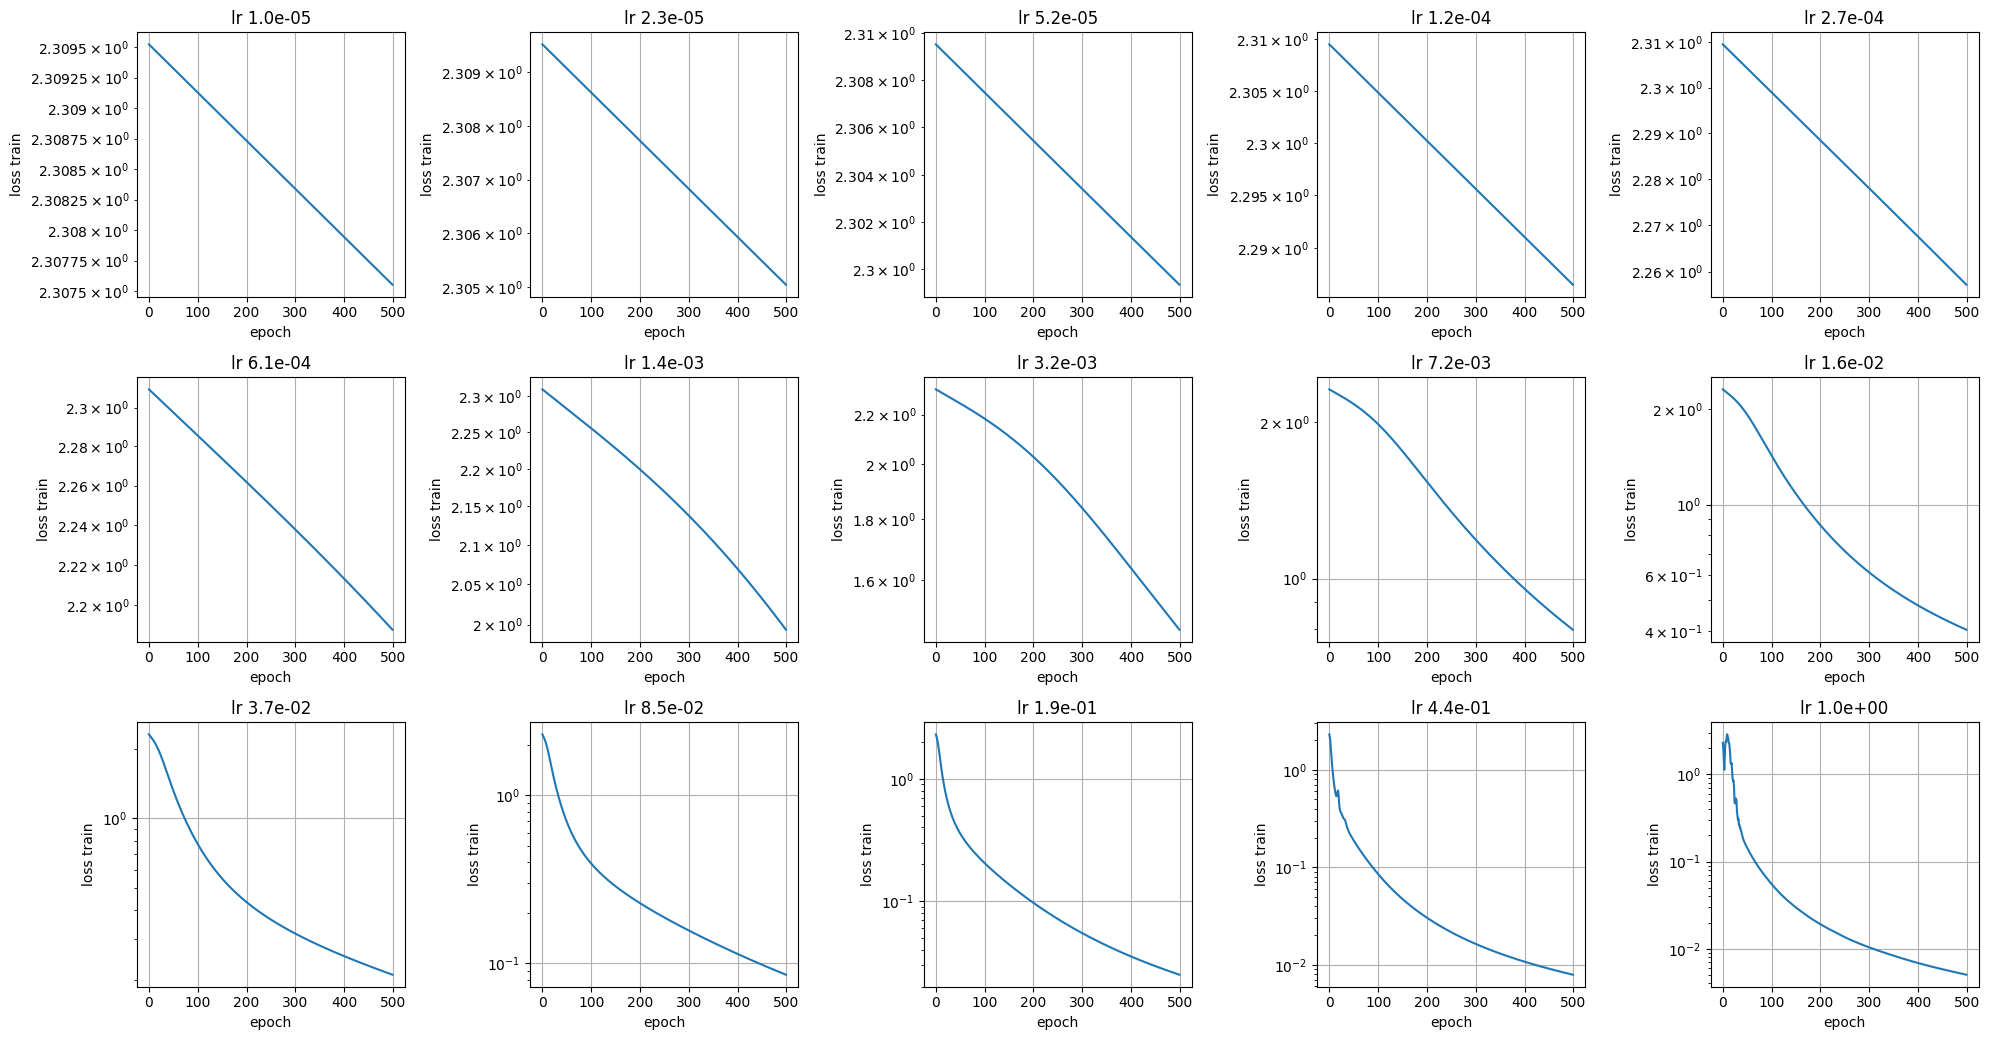

In [ ]:
fig, axes = plt.subplots(3, 5, figsize=(20, 10.5))
for ax, lr in zip(axes.flatten(), lrs):
    n_epochs = len(histories[(lr, seeds[0])])
    mean_curve = []
    for epoch in range(n_epochs):
        total = 0.0
        for s in seeds:
            total += histories[(lr, s)][epoch]
        mean_curve.append(total / len(seeds))
    ax.plot(mean_curve)
    ax.set_title(f"lr {lr:.1e}")
    ax.set_yscale('log')
    ax.set_xlabel('epoch')
    ax.set_ylabel('loss train')
    ax.grid(True)
plt.tight_layout()
plt.show()

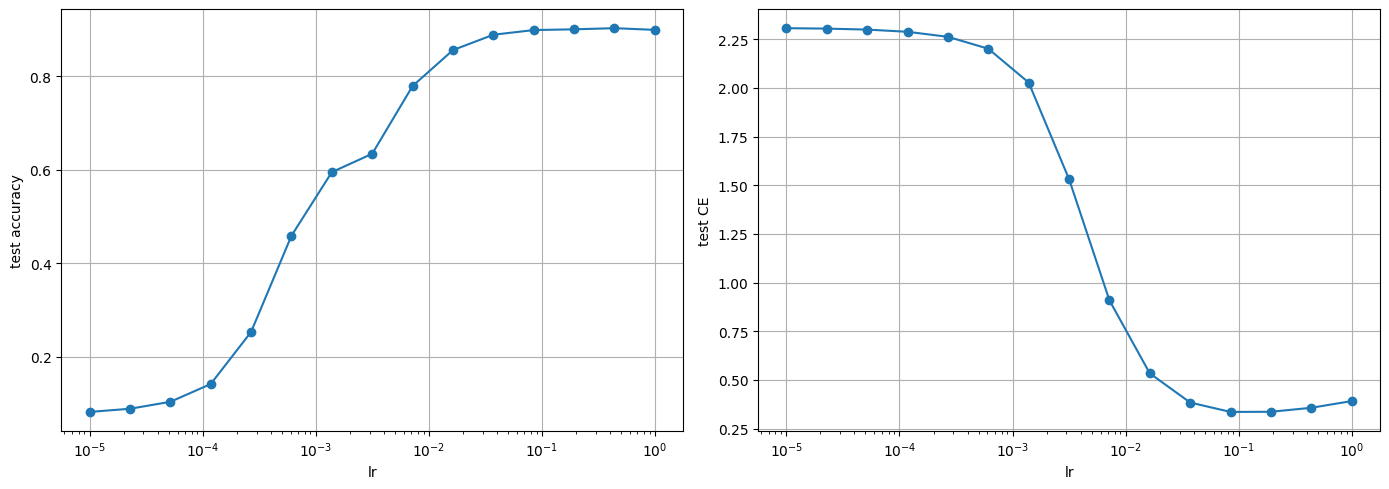

In [ ]:
xs = []
ys_acc = []
ys_ce = []
for r in summary:
    xs.append(r['lr'])
    ys_acc.append(r['acc'])
    ys_ce.append(r['ce'])
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(xs, ys_acc, 'o-')
ax1.set_xscale('log')
ax1.set_xlabel('lr')
ax1.set_ylabel('test accuracy')
ax1.grid(True)

ax2.plot(xs, ys_ce, 'o-')
ax2.set_xscale('log')
ax2.set_xlabel('lr')
ax2.set_ylabel('test CE')
ax2.grid(True)

plt.tight_layout()
plt.show()

Результаты по пункту 2.

Видим, что на всех шагах меньих 0.0006105403881520033 (то есть по факту на первой трети) низкая точность, это явно говорит о недообучении сети, такое просто из-за слишком низкого шага вышло. На значениях близких к 1 точность снова начинает падать. Так что оптимальное окно находиться в окрестности точки с наименьшим лосом на тесте-0.08483429998159409, оптимальное окно начинается с точки с шагом в 0.03727593272924423 и кончается на 0.43939703702926636. Так что окно находится не с краев, как и предполагалось в аналитической части.

Также заметим, что в окне минимальные значения и у стандартного отклонения точности (по сидам), это подтверждает, что окно не случайно такое получилось.

Помимо этого поведение кривых потерь совпало с ожимдаемым-на самых первых просто прямые , а в конце идут уже функции с резким падением в начале и дальнейшей стабилизацией

пункт 3.

В начале зафиксируем параметры T = 600 cosine для и T = Tw = 50 для  warmup+cosine.

Теперь рассмотрим поведение каждой функции шага, считать будем на оптимальном шаге.

step decay

lr(t) = 0.0848 * 0.8^(t/500)

Плавно убывающая кривая, с небольшим наклоном, lr близок к оптимальному.

Exponential decay

lr(t) = 0.0848 * 0.9^t

Резкое падение в первые 50 эпох, далее lr горизонтально идет около нуля, то есть не особо меняется, быстрее учится будет в начале.

Cosine annealing

lr(t) = 0.1^5 + (0.0848 − 0.1^5)/2 * (1 + cos(pi * t / 600))

Плавная кривая, под самый конец горзонтальная около нуля будет линия, так что под конец обычение будет замедляться.

Warmup + cosine

lr(t) = 0.0848 * 0.8^(t/500), t < 50

lr(t) = 0.1^5 + 0.042395 * (1 + cos(pi * (t − 50)/50)), t >= 50

В начале почти горизонтальная линия, затем резкое падение и затем горизонтальная по факту линия около нуля, то есть в начале модель будет довольно эффективно учится, затем веса не будут сильно меняться.

Исходя из анализа графиков, видно, что в основном горизонтальная линия потерь будет у Exponential decay, при чем, начиная с 50 эпохи, с нее потери не будут особо меняться, а вот у step decay не будет уже горизонтальных линий, будет близко к константному проходу.

In [ ]:
import math
def lr_constant(lr0):
    return lambda step: lr0
def lr_step(lr0, n=10, steps_max=500, gamma=0.8):
    def f(step):
        step_current = (step // n) * n
        return lr0 * gamma ** (step_current / steps_max)
    return f
def lr_exp(lr0, n=10, gamma=0.9):
    def f(step):
        step_current = (step // n) * n
        return lr0 * gamma ** step_current
    return f
def lr_cosine(lr0, n=10, T=600, lr_min=1e-5):
    def f(step):
        step_current = (step // n) * n
        t = min(step_current, T)#чисто защита на всякий, если за пределы выйдем
        return lr_min + (lr0 - lr_min) / 2 * (1 + math.cos(math.pi * t / T))
    return f
def lr_warmup_cosine(lr0, n=10, Tw=50, steps_max=500, gamma_step=0.8, lr_min=1e-5):
    def f(step):
        step_current = (step // n) * n
        if step_current < Tw:
            return lr0 * gamma_step ** (step_current / steps_max)
        t = min(step_current - Tw, Tw)
        return lr_min + (lr0 - lr_min) / 2 * (1 + math.cos(math.pi * t / Tw))
    return f

In [ ]:
def train_gd(X_tr, y_tr, X_te, y_te, seed, lr_schedule, n_epochs=500, sigma=0.02):
    g = torch.Generator().manual_seed(seed)
    W1 = (torch.randn(784, 64, generator=g) * sigma).requires_grad_(True)
    b1 = torch.zeros(64, requires_grad=True)
    W2 = (torch.randn(64,  10, generator=g) * sigma).requires_grad_(True)
    b2 = torch.zeros(10, requires_grad=True)
    train_losses = []
    for epoch in range(n_epochs):
        logits = forward(X_tr, W1, b1, W2, b2)
        loss = loss_fn(logits, y_tr)
        W1.grad = None
        b1.grad = None
        W2.grad = None
        b2.grad = None
        loss.backward()
        lr_t = lr_schedule(epoch)
        W1.data = W1.data - lr_t * W1.grad
        b1.data = b1.data - lr_t * b1.grad
        W2.data = W2.data - lr_t * W2.grad
        b2.data = b2.data - lr_t * b2.grad
        train_losses.append(loss.item())
    with torch.no_grad():
        logits_te = forward(X_te, W1, b1, W2, b2)
    final = classification_metrics(y_te, logits_te)
    return train_losses, final

In [ ]:
seeds = [42, 0, 1, 2, 3]
lr0_opt = 0.0848
lr0_high = 0.4
rows, histories = [], {}
schedules_list = ['constant', 'step', 'exp', 'cosine', 'warmup_cosine']
schedules_opt = {
    'constant': lr_constant(lr0_opt),
    'step': lr_step(lr0_opt, steps_max=500, gamma=0.8),
    'exp': lr_exp(lr0_opt, gamma=0.9),
    'cosine': lr_cosine(lr0_opt, T=600, lr_min=1e-5),
    'warmup_cosine': lr_warmup_cosine(lr0_opt, Tw=50, steps_max=500, gamma_step=0.8, lr_min=1e-5),
}
for name, fn in schedules_opt.items():
    for s in seeds:
        tr_loss, final = train_gd(X_train, y_train, X_test, y_test, seed=s, lr_schedule=fn)
        rows.append({
            'level': 'lr0_opt',
            'lr0': lr0_opt,
            'schedule': name,
            'seed': s,
            'acc': final['acc'],
            'prec': final['prec'],
            'rec': final['rec'],
            'f1': final['f1'],
            'ce': final['ce'],
        })
        histories[('lr0_opt', name, s)] = tr_loss
schedules_high = {
    'constant': lr_constant(lr0_high),
    'step': lr_step(lr0_high, steps_max=500, gamma=0.8),
    'exp': lr_exp(lr0_high, gamma=0.9),
    'cosine': lr_cosine(lr0_high, T=600, lr_min=1e-5),
    'warmup_cosine': lr_warmup_cosine(lr0_high, Tw=50, steps_max=500, gamma_step=0.8, lr_min=1e-5),
}
for name, fn in schedules_high.items():
    for s in seeds:
        tr_loss, final = train_gd(X_train, y_train, X_test, y_test, seed=s, lr_schedule=fn)
        rows.append({
            'level': 'lr0_high',
            'lr0': lr0_high,
            'schedule': name,
            'seed': s,
            'acc': final['acc'],
            'prec': final['prec'],
            'rec': final['rec'],
            'f1': final['f1'],
            'ce': final['ce'],
        })
        histories[('lr0_high', name, s)] = tr_loss

In [ ]:
summary = []
for name in schedules_list:
    n = 0
    s_acc = sq_acc = s_prec = s_rec = s_f1 = s_ce = sq_ce = 0.0
    acc_min = float('inf')
    acc_max = float('-inf')
    for r in rows:
        if r['level'] == 'lr0_opt' and r['schedule'] == name:
            s_acc  += r['acc']
            sq_acc += r['acc'] ** 2
            s_prec += r['prec']
            s_rec += r['rec']
            s_f1 += r['f1']
            s_ce += r['ce']
            sq_ce += r['ce'] ** 2
            n += 1
            if r['acc'] < acc_min: acc_min = r['acc']
            if r['acc'] > acc_max: acc_max = r['acc']
    mean_acc = s_acc / n
    std_acc = ((sq_acc - n * mean_acc ** 2) / (n - 1)) ** 0.5
    mean_ce = s_ce / n
    std_ce = ((sq_ce - n * mean_ce ** 2) / (n - 1)) ** 0.5
    summary.append({
        'level': 'lr0_opt',
        'lr0': lr0_opt,
        'schedule': name,
        'acc': mean_acc,
        'acc_std': std_acc,
        'acc_min': acc_min,
        'acc_max': acc_max,
        'prec': s_prec / n,
        'rec': s_rec / n,
        'f1': s_f1 / n,
        'ce': mean_ce,
        'ce_std': std_ce,
    })
for name in schedules_list:
    n = 0
    s_acc = sq_acc = s_prec = s_rec = s_f1 = s_ce = sq_ce = 0.0
    acc_min = float('inf')
    acc_max = float('-inf')
    for r in rows:
        if r['level'] == 'lr0_high' and r['schedule'] == name:
            s_acc += r['acc']
            sq_acc += r['acc'] ** 2
            s_prec += r['prec']
            s_rec += r['rec']
            s_f1 += r['f1']
            s_ce += r['ce']
            sq_ce += r['ce'] ** 2
            n += 1
            if r['acc'] < acc_min: acc_min = r['acc']
            if r['acc'] > acc_max: acc_max = r['acc']
    mean_acc = s_acc / n
    std_acc = ((sq_acc - n * mean_acc ** 2) / (n - 1)) ** 0.5
    mean_ce = s_ce / n
    std_ce = ((sq_ce - n * mean_ce ** 2) / (n - 1)) ** 0.5
    summary.append({
        'level': 'lr0_high',
        'lr0': lr0_high,
        'schedule': name,
        'acc': mean_acc,
        'acc_std': std_acc,
        'acc_min': acc_min,
        'acc_max': acc_max,
        'prec': s_prec / n,
        'rec': s_rec / n,
        'f1': s_f1 / n,
        'ce': mean_ce,
        'ce_std': std_ce,
    })
for r in summary:
    print(f"{r['level']}  {r['schedule']}  acc {r['acc']} acc_std {r['acc_std']} f1 {r['f1']}  ce {r['ce']} ce_std {r['ce_std']}")

lr0_opt  constant  acc 0.8984 acc_std 0.005549774770204418 f1 0.8982030099630871  ce 0.3352374076843262 ce_std 0.006051872046554394
lr0_opt  step  acc 0.8956 acc_std 0.0049799598392225065 f1 0.8953975215814175  ce 0.3379975318908691 ce_std 0.006041004629889157
lr0_opt  exp  acc 0.6156 acc_std 0.022289010745208487 f1 0.5631851914195296  ce 1.6970457315444947 ce_std 0.02051079839220794
lr0_opt  cosine  acc 0.8936 acc_std 0.003847076812346293 f1 0.8934050946936519  ce 0.35656796097755433 ce_std 0.006039869243269521
lr0_opt  warmup_cosine  acc 0.8455999999999999 acc_std 0.006985699678650168 f1 0.8449676815856962  ce 0.5962723135948181 ce_std 0.0073581032878031905
lr0_high  constant  acc 0.898 acc_std 0.0058309518948529765 f1 0.8978233178914895  ce 0.35490489602088926 ce_std 0.009554646487682245
lr0_high  step  acc 0.8987999999999999 acc_std 0.006418722614358289 f1 0.8986254774159355  ce 0.35157098770141604 ce_std 0.009044633865515272
lr0_high  exp  acc 0.8388 acc_std 0.00540370243443803 f1

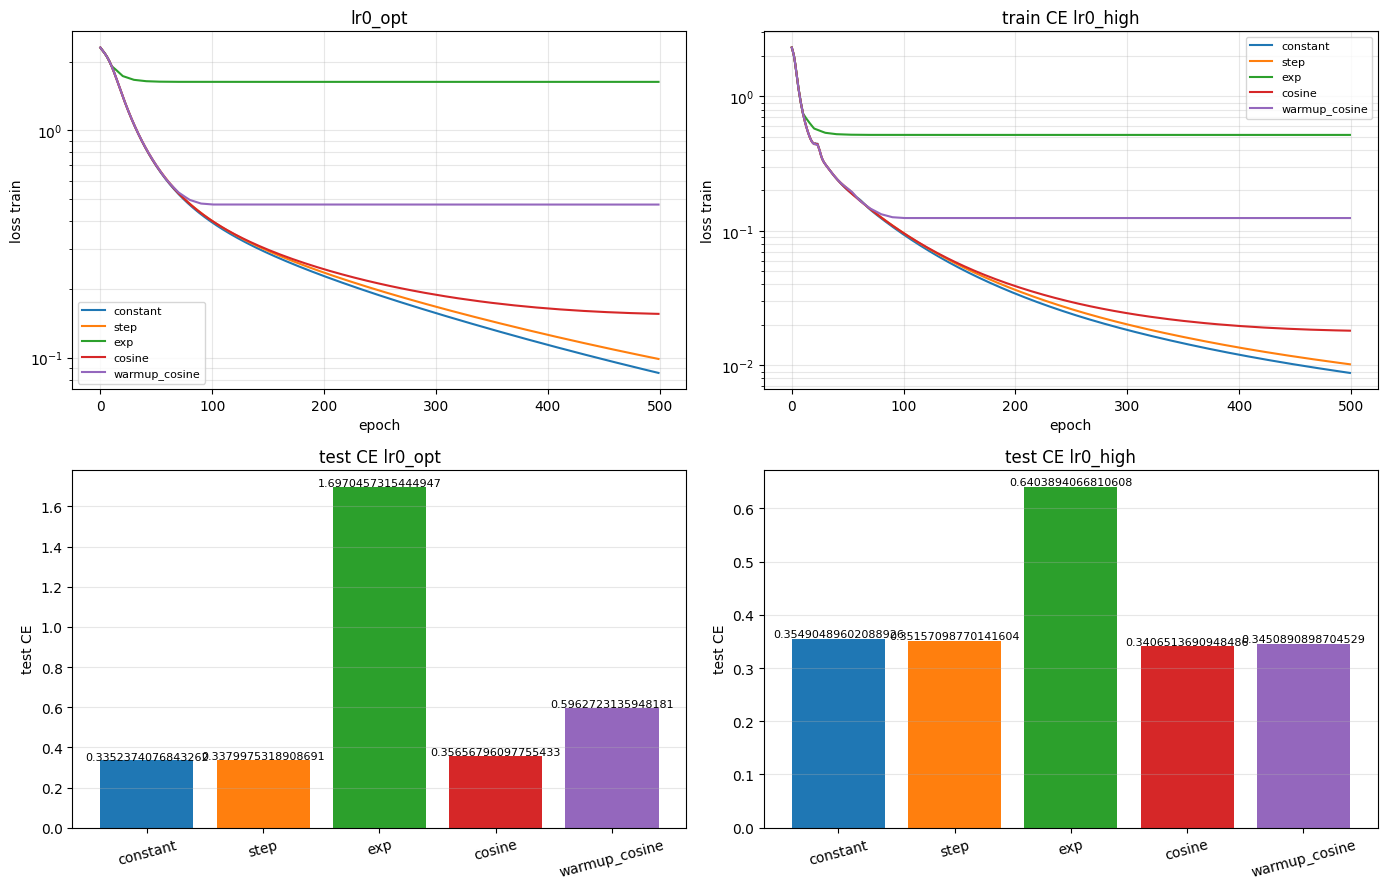

In [ ]:
colors = {
    'constant': 'C0',
    'step': 'C1',
    'exp': 'C2',
    'cosine': 'C3',
    'warmup_cosine': 'C4',
}
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
ax = axes[0, 0]
for name in schedules_list:
    n_epochs = len(histories[('lr0_opt', name, seeds[0])])
    mean_curve = []
    for epoch in range(n_epochs):
        total = 0.0
        for s in seeds:
            total += histories[('lr0_opt', name, s)][epoch]
        mean_curve.append(total / len(seeds))
    ax.plot(mean_curve, label=name)
ax.set_yscale('log')
ax.set_xlabel('epoch')
ax.set_ylabel('loss train')
ax.set_title("lr0_opt")
ax.legend(fontsize=8)
ax.grid(True, which='both', alpha=0.3)
ax = axes[1, 0]
means_opt = []
for name in schedules_list:
    total = 0.0
    n = 0
    for r in rows:
        if r['level'] == 'lr0_opt' and r['schedule'] == name:
            total += r['ce']
            n += 1
    means_opt.append(total / n)
ax.bar(range(len(means_opt)), means_opt, color=[colors[n] for n in schedules_list])
ax.set_xticks(range(len(means_opt)))
ax.set_xticklabels(schedules_list, rotation=15)
ax.set_ylabel('test CE')
ax.set_title(f"test CE lr0_opt")
ax.grid(True, axis='y', alpha=0.3)
for i, m in enumerate(means_opt):
    ax.text(i, m + 0.003, f"{m}", ha='center', fontsize=8)
ax = axes[0, 1]
for name in schedules_list:
    n_epochs = len(histories[('lr0_high', name, seeds[0])])
    mean_curve = []
    for epoch in range(n_epochs):
        total = 0.0
        for s in seeds:
            total += histories[('lr0_high', name, s)][epoch]
        mean_curve.append(total / len(seeds))
    ax.plot(mean_curve, label=name)
ax.set_yscale('log')
ax.set_xlabel('epoch')
ax.set_ylabel('loss train')
ax.set_title("train CE lr0_high")
ax.legend(fontsize=8)
ax.grid(True, which='both', alpha=0.3)

ax = axes[1, 1]
means_high = []
for name in schedules_list:
    total = 0.0
    n = 0
    for r in rows:
        if r['level'] == 'lr0_high' and r['schedule'] == name:
            total += r['ce']
            n += 1
    means_high.append(total / n)
ax.bar(range(len(means_high)), means_high, color=[colors[n] for n in schedules_list])
ax.set_xticks(range(len(means_high)))
ax.set_xticklabels(schedules_list, rotation=15)
ax.set_ylabel('test CE')
ax.set_title(f"test CE lr0_high")
ax.grid(True, axis='y', alpha=0.3)
for i, m in enumerate(means_high):
    ax.text(i, m + 0.003, f"{m}", ha='center', fontsize=8)
plt.tight_layout()
plt.show()

Выводы по пункту 3.

Из статистик видно, что на оптимальном фиксированном шаге лучше всего проявил себя константный, но step и cosine тоже похожие результаты дали, а на высоком шаге уже лучше всего проявил себя cosine, но и у остальных, кроме exp, результаты похожие.

Также на графиках видно,  что exp хуже всего получился, это из-за того, что он слишком рано шаг обучения около нуля делает, так что и потери не особо меняться будут на графиках. И собственно подтвердилась наша гипотеза, что у exp будет скорее горизонтальная прямая, а у step decay будет плавно до конца снижаться график.

Пункт 4.

Попробуем оценить, как будет выглядеть зависимость L потерь от lr, а затем на основе этого примерно определить, где у нас будет nan.

L=-log(p_y), p_y=e^(z_y)/sum(e^(z_i)).

L=-z_y+log(sum(e^(z_i))), dL/dz_k=-q_ky+p_k, где q_ky-символ кронекера

Ввиду того что p_k, q_ky принимают значения на [0,1], {0, 1} соответственно получаем, что |p_k-q_ky|<=1, то есть градиент по логитам ограничена 1.

z=W2a+b2, a=tanh(z_1), которая тоже по абсолютному значению не превосходит 1.

dL/dW2_kj=(dL/dz_k)*(dz_k/dW2_kj)=(p_k-y_k)*a_j, тут видно, что каждый множитель по абсолютному не более 1, так что и градиент по весам W2 тоже 1 ограничен по абсолбтному значению.

W2:=W2-n(p-q)*a, тут тоже при больших шагах n доминирвоание будет над остальными множителями (так как они как выше написано не превосходят 1 по абсолютному), а первое слагаемое меньше шага (так как последний достаточно большой), то получаем. что можно считать, что новый вес |W2| примерно n и будет равняться.

После шага z=W2* a+b2 вот это вот значение опять по факту зависит именно от W2 по тем же причинам, что и выше. А значит можно считать: |z|<=|W2|*|a|+|b2|, а последнее будет по аналогичным причинам от n линейно зависеть. Так что можно уже на основе этого заключить, что рост логита будет линейно от n  зависеть.

L=-z_y+log(sum(e^z_i))<=-z_y+max(z_i)+log K, и тут каждое слагаемое линейно от n зависит, так что и L линейно от n зависит, то есть L=O(n).

у float32 в питоне максимум примерно на 3.4* 10^38, так что пользуясь линейностю от шага, можно сразу же сказать, что значение шага на котором достигнется nan n_nan примерно и будет где-то в районе 3.4*10^38.

Таким образом, можно сказать, что в эксперименте у нас будет прямая расти линейно, а вот для значения, где nan уже достигнут имеет смысл 10^40 выбрать, что мы и сделаем ниже в эксперименте в качетсве верхней границы (дальше просто пойдут значения nan и смысла продолжать рассматривать шаги и далее нет)

In [ ]:
seeds = [42, 0, 1, 2, 3]
lrs_p4 = (10 ** np.linspace(-1, 40, 10)).tolist()
rows_p4 = []
for lr in lrs_p4:
    for s in seeds:
        tr_loss, final = train_gd(X_train, y_train, X_test, y_test, seed=s, lr_schedule=lr_constant(lr))
        rows_p4.append({
            'lr': lr,
            'seed': s,
            'acc': final['acc'],
            'ce': final['ce'],
        })

lr 0.1 ce 0.3325609087944031
lr 3593.813663804626 ce 19345.1841796875
lr 129154966.50148827 ce 52196188.8
lr 4641588833612.772 ce 2060682710220.8
lr 1.6681005372000557e+17 ce 6.376678673822515e+16
lr 5.994842503189421e+21 ce 2.2570848441429627e+21
lr 2.1544346900318778e+26 ce 8.411609044365692e+25
lr 7.742636826811215e+30 ce 2.814469312590127e+30
lr 2.7825594022071144e+35 ce 1.0295718832522858e+35
lr 1e+40 ce nan


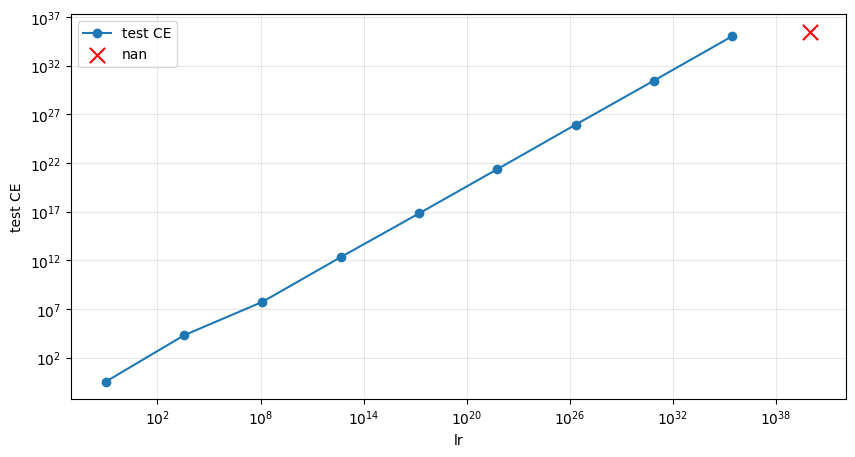

In [ ]:
summary_p4 = []
for lr in lrs_p4:
    total = 0.0
    for r in rows_p4:
        if r['lr'] == lr:
            total += r['ce']
    summary_p4.append({'lr': lr, 'ce': total / 5})
for r in summary_p4:
    print(f"lr {r['lr']} ce {r['ce']}")
finite_lrs, finite_ce, nan_lrs = [], [], []
for r in summary_p4:
    if math.isnan(r['ce']):
        nan_lrs.append(r['lr'])
    else:
        finite_lrs.append(r['lr'])
        finite_ce.append(r['ce'])
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(finite_lrs, finite_ce, 'o-', label='test CE')
if nan_lrs:
    y_top = max(finite_ce) * 3 if finite_ce else 10.0
    ax.scatter(nan_lrs, [y_top] * len(nan_lrs), marker='x', s=120, color='red', label='nan')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('lr')
ax.set_ylabel('test CE')
ax.legend()
ax.grid(True, which='both', alpha=0.3)
plt.show()

Вывод по 4 пункту.

В аналитической части мы получили, что у нас (в конкретно нашей модели и по нашему лоссу) будет график функции потерь линейно зависеть от скорости обучения, а значение nan будет примерно там же, где и у питона float32 будет nan, а это примерно 3.4* 10^38.

В экспериментальной части мы видим, что у нас график становится по факту прямой на достаточно больших значениях скорости, что совпадает с предположением нашим выше. А значение nan появилось как раз на моменте, где и у питона float32 будет максимальным. Так что можно сделать вывод, что эксперимент подтвердил анализ

Пункт 5.

Тут такого анализа, как в пункте 3 с предугадыванием шага не выйдет сделать, так как алгоритм на месте сам подстравиваться будет по ситуации.

Стоит отметить, что здесь мы используем валидационную выборку во время тренировки, так как на тренировочной наклон будет всегда, но он на плато становится меньше. Как раз возможна ситуация, когда находимся у минимума, тогда возникает плато, и тогда по текущей скорости мы просто будем прыгать около минимума и не уйдем еще ниже (особенно это будет видно на высоких скоростях обучения), так что скорость надо замедлить, а тренировачная не скажет на плато ли мы. И такие моменты и поможет выявить валидационная-когда у нас возникло плато. Того следует ожидать, что на высоких скоростях обучения нам такая подстройка поможет, также чем выше начальная скорость обучения, тем больше будет изменений в скоростях

In [ ]:
n_tr = int(0.8 * len(X_train))
X_tr_sub = X_train[:n_tr]
y_tr_sub = y_train[:n_tr]
X_val_sub = X_train[n_tr:]
y_val_sub = y_train[n_tr:]
def train_gd_plateau(X_tr, y_tr, X_val, y_val, X_te, y_te, seed, lr0, patience=10, factor=0.5, min_lr=1e-4, n_epochs=500, sigma=0.02):
    g = torch.Generator().manual_seed(seed)
    W1 = (torch.randn(784, 64, generator=g) * sigma).requires_grad_(True)
    b1 = torch.zeros(64, requires_grad=True)
    W2 = (torch.randn(64, 10, generator=g) * sigma).requires_grad_(True)
    b2 = torch.zeros(10, requires_grad=True)
    train_losses = []
    lr_history = []
    cur_lr = lr0
    best_val = float('inf')
    wait = 0
    for epoch in range(n_epochs):
        logits = forward(X_tr, W1, b1, W2, b2)
        loss = loss_fn(logits, y_tr)
        W1.grad = None
        b1.grad = None
        W2.grad = None
        b2.grad = None
        loss.backward()
        W1.data = W1.data - cur_lr * W1.grad
        b1.data = b1.data - cur_lr * b1.grad
        W2.data = W2.data - cur_lr * W2.grad
        b2.data = b2.data - cur_lr * b2.grad
        train_losses.append(loss.item())
        lr_history.append(cur_lr)
        with torch.no_grad():
            val_ce = loss_fn(forward(X_val, W1, b1, W2, b2), y_val).item()
        if val_ce < best_val - 1e-4:
            best_val = val_ce
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                cur_lr = max(cur_lr * factor, min_lr)
                wait = 0
    with torch.no_grad():
        logits_te = forward(X_te, W1, b1, W2, b2)
    final = classification_metrics(y_te, logits_te)
    return train_losses, lr_history, final
seeds = [42, 0, 1, 2, 3]
lr_values = [1e-3, 0.0848, 0.4, 1.0]

rows = []
hist_plateau = {}
for lr0 in lr_values:
    for s in seeds:
        tr, final = train_gd(X_tr_sub, y_tr_sub, X_test, y_test, seed=s, lr_schedule=lr_constant(lr0))
        rows.append({'lr0': lr0,
                     'method': 'constant',
                     'seed': s,
                     'acc': final['acc'],
                     'f1': final['f1'],
                     'ce': final['ce']})

    for s in seeds:
        tr, lrh, final = train_gd_plateau(X_tr_sub, y_tr_sub, X_val_sub, y_val_sub, X_test, y_test, seed=s, lr0=lr0)
        rows.append({'lr0': lr0,
                     'method': 'plateau',
                     'seed': s,
                     'acc': final['acc'],
                     'f1': final['f1'],
                     'ce': final['ce']})
        hist_plateau[(lr0, s)] = (tr, lrh)


0.001 constant acc  0.5524 acc_std 0.024347484469654353 f1 0.5043703062101724 ce 2.127805233001709 ce_std 0.014713854468534104
0.001 plateau acc  0.5524 acc_std 0.024347484469654353 f1 0.5043703062101724 ce 2.127805233001709 ce_std 0.014713854468534104
0.0848 constant acc  0.8952 acc_std 0.005403702434458575 f1 0.8951960280783628 ce 0.3543392181396484 ce_std 0.0059712343864911435
0.0848 plateau acc  0.8952 acc_std 0.005403702434458575 f1 0.8951960280783628 ce 0.3543392181396484 ce_std 0.0059712343864911435
0.4 constant acc  0.892 acc_std 0.006782329983124567 f1 0.8919281721792807 ce 0.3767271459102631 ce_std 0.008096135583118317
0.4 plateau acc  0.8936 acc_std 0.006228964600968328 f1 0.893458782847435 ce 0.35270853638648986 ce_std 0.006719368937619902
1.0 constant acc  0.8976000000000001 acc_std 0.005176871642206563 f1 0.8977195217811111 ce 0.37234394550323485 ce_std 0.013025399949620734
1.0 plateau acc  0.8936 acc_std 0.010334408546214606 f1 0.8936432817303575 ce 0.3578855752944946 ce

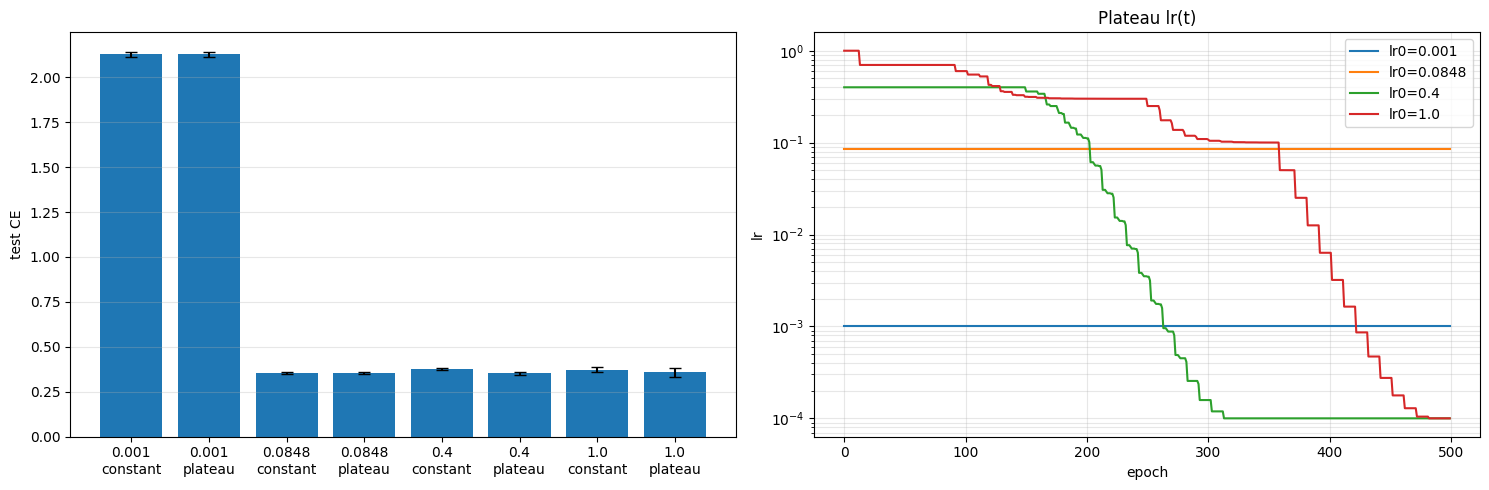

In [ ]:
for lr0 in lr_values:
    for method in ['constant', 'plateau']:
        n = s_acc = sq_acc = s_f1  = s_ce  = sq_ce  = 0.0
        for r in rows:
            if r['lr0'] == lr0 and r['method'] == method:
                s_acc += r['acc']
                sq_acc += r['acc'] ** 2
                s_f1 += r['f1']
                s_ce += r['ce']
                sq_ce += r['ce'] ** 2
                n += 1
        ma = s_acc / n
        sa = ((sq_acc - n * ma * ma) / (n - 1)) ** 0.5
        mf = s_f1 / n
        mc = s_ce / n
        sc = ((sq_ce - n * mc * mc) / (n - 1)) ** 0.5
        print(f"{lr0} {method} acc  {ma} acc_std {sa} f1 {mf} ce {mc} ce_std {sc}")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
labels = []
means, stds = [], []
for lr0 in lr_values:
    for method in ['constant', 'plateau']:
        labels.append(f"{lr0}\n{method}")
        n = s_ce = sq_ce = 0.0
        for r in rows:
            if r['lr0'] == lr0 and r['method'] == method:
                s_ce += r['ce']
                sq_ce += r['ce'] ** 2
                n += 1
        m = s_ce / n
        s = ((sq_ce - n * m * m) / (n - 1)) ** 0.5
        means.append(m)
        stds.append(s)
ax1.bar(labels, means, yerr=stds, capsize=4)
ax1.set_ylabel('test CE')
ax1.grid(True, axis='y', alpha=0.3)

for lr0 in lr_values:
    n_epochs = len(hist_plateau[(lr0, seeds[0])][1])
    mean_lrh = []
    for e in range(n_epochs):
        total = 0.0
        for s in seeds:
            total += hist_plateau[(lr0, s)][1][e]
        mean_lrh.append(total / len(seeds))
    ax2.plot(mean_lrh, label=f'lr0={lr0}')
ax2.set_yscale('log')
ax2.set_xlabel('epoch')
ax2.set_ylabel('lr')
ax2.set_title('Plateau lr(t)')
ax2.legend()
ax2.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()

Вывод по пункту 5.

Видим, что на небольших скоростях обучения подстройка никак не помогла, а на больших видим некоторое улучшение.

Также на 2 графике видим, что на малых скоростях никак не изменилась скорость обучения, а на больших уже менялась. Это говорит как раз, что данный метод следует использовать на достаточно больших скоростях обучения, чтобы затем ее подстроить под ситуацию, что и совпало с нашим предвариельным анализом.

Вывод (контрольные вопросы).

1. У глубокой сети градиенты по разным слоям могут иметь разные масштабы, так что скорость обучения для одного слоя может быть хорошей, а для друого уже нет. И в первые эпохи Warmup поможет слоям выровняться в этом плане. Также на старте (при начальных весах) не ясно поведение функции потерь, и небольшой шаг в начале помогает нам аккуратно выйти из такой ситуации, то есть избегает нестабильности на старте обучения, особенно на больших сетях. Также в пункте 3 мы увидели, что на небольшой сети Warmup + cosine не помог.

2. Конкретно ранее размер батча я никак не менял (был обычный градиентный спуск, что достаточно для всех пунктов). Но можно предположить, что на малых по размерам батчах градиент более шумный и будет чаще обновлять веса, так что с ростом размера батча обновление весов будет реже, будет более стабильно. Поэтому есть эмпирическое правило: при увеличении размера батча в n раз, увеличиваем скорость обучения в это же число раз.

Вывод (общие вопросы, выводы по пунктам вкратце).
1. Модель была успешно обучена.

2. Оптимальное окно шага для выбранных датасета и сети составляет (0.038, 0.439). Также в окне у стандартного отклонения точности минимальные значения.

3. Исходя из анализа статистик, расписания были полезны на больших значениях начальной скорости обучения.

4. Начиная с достаточно большого шага, начнется расходимость функции потерь.

5. Также уменьшение скорости обучения при плато помогла нам на больших значениях начальной скорости обучения, но на других шагах никак не сделало хуже.